# **ANÁLISIS DE POSICIONAMIENTO EN YOUTUBE**


## 1. Contexto

El posicionamiento en plataformas como YouTube representa una oportunidad para entender las preferencias de la audiencia y encontrar patrones de consumo. El objetivo es analizar los videos que fueron tendencia en Estados Unidos, con el fin de identificar patrones asociados con su popularidad, la interacción de los usuarios, el comportamiento, las diferencias entre categorías y las visualizaciones.

A partir de un análisis exploratorio y mediante la aplicación de la ciencia de datos, el propósito es encontrar información que permita entender mejor el comportamiento de los videos en tendencia y, con ello, tomar decisiones.

### Objetivos específicos

* Identificar las categorías y los canales con mayor presencia en Trending.
* Analizar el comportamiento de las visualizaciones y las interacciones de los usuarios.
* Estudiar cuánto tiempo transcurre entre la publicación de un video y su primera aparición en Trending.
* Identificar patrones de comportamiento entre diferentes tipos de contenido.
* Evaluar la posibilidad de desarrollar modelos que permitan caracterizar o estimar el comportamiento de los videos.

## 2. Importación de datos

In [1]:
from pathlib import Path
import sys

ROOT_DIR = Path.cwd().parent
sys.path.insert(0, str(ROOT_DIR))

from utils.kaggle_utils import import_data

us_videos = import_data('USvideos.csv')
us_category_id = import_data('US_category_id.json')


/home/json/Documents/pragma_test/.venv/lib/python3.15/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 3. Analisís Inicial

In [2]:
from IPython.display import display
import warnings
warnings.filterwarnings("ignore")

print("USvideos size:", us_videos.shape)
print("USvideos size unique rows:", us_videos.drop_duplicates(inplace=False).shape)
print("US_category_id size:", us_category_id.shape)
print("_____________________________________________________________")
print("USvideos columns:", us_videos.columns.tolist())
print("US_category_id columns:", us_category_id.columns.tolist())
print("_____________________________________________________________")
display(us_videos.head())
display(us_category_id.head())
print("_____________________________________________________________")
us_videos.info()
us_category_id.info()
print("_____________________________________________________________")
us_videos.drop_duplicates(inplace=False).isnull().sum()



USvideos size: (40949, 16)
USvideos size unique rows: (40901, 16)
US_category_id size: (32, 3)
_____________________________________________________________
USvideos columns: ['video_id', 'trending_date', 'title', 'channel_title', 'category_id', 'publish_time', 'tags', 'views', 'likes', 'dislikes', 'comment_count', 'thumbnail_link', 'comments_disabled', 'ratings_disabled', 'video_error_or_removed', 'description']
US_category_id columns: ['kind', 'etag', 'items']
_____________________________________________________________


,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description
0,2kyS6SvSYSE,17.14.11,WE WANT TO TALK ABOUT OUR MARRIAGE,CaseyNeistat,22,2017-11-13T17:13:01.000Z,SHANtell martin,748374,57527,2966,15954,https://i.ytimg.com/vi/2kyS6SvSYSE/default.jpg,False,False,False,SHANTELL'S CHANNEL - https://www.youtube.com/s...
1,1ZAPwfrtAFY,17.14.11,The Trump Presidency: Last Week Tonight with J...,LastWeekTonight,24,2017-11-13T07:30:00.000Z,"last week tonight trump presidency|""last week ...",2418783,97185,6146,12703,https://i.ytimg.com/vi/1ZAPwfrtAFY/default.jpg,False,False,False,"One year after the presidential election, John..."
2,5qpjK5DgCt4,17.14.11,"Racist Superman | Rudy Mancuso, King Bach & Le...",Rudy Mancuso,23,2017-11-12T19:05:24.000Z,"racist superman|""rudy""|""mancuso""|""king""|""bach""...",3191434,146033,5339,8181,https://i.ytimg.com/vi/5qpjK5DgCt4/default.jpg,False,False,False,WATCH MY PREVIOUS VIDEO ▶ \n\nSUBSCRIBE ► http...
3,puqaWrEC7tY,17.14.11,Nickelback Lyrics: Real or Fake?,Good Mythical Morning,24,2017-11-13T11:00:04.000Z,"rhett and link|""gmm""|""good mythical morning""|""...",343168,10172,666,2146,https://i.ytimg.com/vi/puqaWrEC7tY/default.jpg,False,False,False,Today we find out if Link is a Nickelback amat...
4,d380meD0W0M,17.14.11,I Dare You: GOING BALD!?,nigahiga,24,2017-11-12T18:01:41.000Z,"ryan|""higa""|""higatv""|""nigahiga""|""i dare you""|""...",2095731,132235,1989,17518,https://i.ytimg.com/vi/d380meD0W0M/default.jpg,False,False,False,I know it's been a while since we did this sho...


,kind,etag,items
0,youtube#videoCategoryListResponse,"""m2yskBQFythfE4irbTIeOgYYfBU/S730Ilt-Fi-emsQJv...","{'kind': 'youtube#videoCategory', 'etag': '""m2..."
1,youtube#videoCategoryListResponse,"""m2yskBQFythfE4irbTIeOgYYfBU/S730Ilt-Fi-emsQJv...","{'kind': 'youtube#videoCategory', 'etag': '""m2..."
2,youtube#videoCategoryListResponse,"""m2yskBQFythfE4irbTIeOgYYfBU/S730Ilt-Fi-emsQJv...","{'kind': 'youtube#videoCategory', 'etag': '""m2..."
3,youtube#videoCategoryListResponse,"""m2yskBQFythfE4irbTIeOgYYfBU/S730Ilt-Fi-emsQJv...","{'kind': 'youtube#videoCategory', 'etag': '""m2..."
4,youtube#videoCategoryListResponse,"""m2yskBQFythfE4irbTIeOgYYfBU/S730Ilt-Fi-emsQJv...","{'kind': 'youtube#videoCategory', 'etag': '""m2..."


_____________________________________________________________
<class 'pandas.DataFrame'>
RangeIndex: 40949 entries, 0 to 40948
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   video_id                40949 non-null  str  
 1   trending_date           40949 non-null  str  
 2   title                   40949 non-null  str  
 3   channel_title           40949 non-null  str  
 4   category_id             40949 non-null  int64
 5   publish_time            40949 non-null  str  
 6   tags                    40949 non-null  str  
 7   views                   40949 non-null  int64
 8   likes                   40949 non-null  int64
 9   dislikes                40949 non-null  int64
 10  comment_count           40949 non-null  int64
 11  thumbnail_link          40949 non-null  str  
 12  comments_disabled       40949 non-null  bool 
 13  ratings_disabled        40949 non-null  bool 
 14  video_error_or_remo

video_id                    0
trending_date               0
title                       0
channel_title               0
category_id                 0
publish_time                0
tags                        0
views                       0
likes                       0
dislikes                    0
comment_count               0
thumbnail_link              0
comments_disabled           0
ratings_disabled            0
video_error_or_removed      0
description               569
dtype: int64

In [3]:
us_category_id.isnull().sum()

kind     0
etag     0
items    0
dtype: int64

En el análisis inicial se revisó la información de cada tabla:

**USvideos.csv:** Contiene 16 columnas y 40.949 registros, aunque hay 48 duplicados en todas sus columnas, por lo que la cantidad final de filas es 40.901. Esta tabla contiene datos como `video_id`, `trending_date`, `title`, `channel_title`, `category_id`, `publish_time`, `tags`, `views`, `likes`, `dislikes`, `comment_count`, `thumbnail_link`, `comments_disabled`, `ratings_disabled`, `video_error_or_removed` y `description`, cuyos nombres son bastante dicientes sobre los datos que los componen. Los tipos de datos deben ser casteados para su correcto uso y solo se encontraron 570 valores nulos en la columna `description`.

**US_category_id.json:** Contiene el catálogo de categorías de YouTube en formato JSON. Incluye información como el identificador de cada categoría (`id`), su nombre (`title`) y un atributo que indica si la categoría puede asignarse (`assignable`). Esta información permite interpretar los valores de `category_id` presentes en los registros de videos y facilitar su clasificación y análisis por categoría.

Para el análisis de los datos se utilizará PostgreSQL, ya que facilita las consultas y la transformación de datos, particularmente en las funciones de agregación, operaciones con fechas y análisis temporal. Además se parseara el json de la tabla US_category_id antes de cargarla en la base de datos.

In [4]:
import pandas as pd
from utils.postgres_utils import write_to_postgres, read_from_postgres

us_category_id_parsed = pd.json_normalize(
    us_category_id["items"].tolist(),
    sep="_",
).rename(columns={
    "snippet_title": "title",
    "snippet_assignable": "assignable",
})[["id", "title", "assignable"]]
us_category_id_parsed["id"] = us_category_id_parsed["id"].astype("int64")

us_videos_to_load = us_videos.drop_duplicates().copy()
us_videos_to_load["trending_date"] = pd.to_datetime(
    us_videos_to_load["trending_date"], format="%y.%d.%m"
).dt.date
us_videos_to_load["publish_time"] = pd.to_datetime(
    us_videos_to_load["publish_time"], utc=True
).dt.tz_localize(None)


#write_to_postgres("us_videos", us_videos_to_load)
#write_to_postgres("us_category_id", us_category_id_parsed)

Ahora con la data lim

## 4. Limpieza y validación 

### 4.1 Consolidación de video y fechas de tendencia

In [5]:
path_duplicate_video_dates = './queries/01_identify_duplicate_video_dates.sql'
duplicate_video_dates = read_from_postgres(ROOT_DIR / path_duplicate_video_dates)
display(duplicate_video_dates)
path_us_video_daily = './queries/02_consolidate_video_date_records.sql'
us_videos_daily = read_from_postgres(ROOT_DIR / path_us_video_daily)
#write_to_postgres("us_videos_daily", us_videos_daily)
path_video_date_granularity = './queries/03_validate_video_date_granularity.sql'
video_date_granularity = read_from_postgres(ROOT_DIR / path_video_date_granularity)
display(video_date_granularity)


,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description
0,vY_5EvoL1Is,2018-05-15,NEW AMSTERDAM | Official Trailer | NBC Fall Sh...,New Amsterdam,24,2018-05-13 16:29:57,"New Amsterdam|""NBC""|""2018""|""New Show""|""trailer...",2469801,5084,1719,567,https://i.ytimg.com/vi/vY_5EvoL1Is/default.jpg,f,f,f,Break the rules. Heal the system. The Blacklis...
1,vY_5EvoL1Is,2018-05-15,NEW AMSTERDAM | Official Trailer | NBC Fall Sh...,New Amsterdam,24,2018-05-13 16:29:57,"New Amsterdam|""NBC""|""2018""|""New Show""|""trailer...",2471590,5085,1719,567,https://i.ytimg.com/vi/vY_5EvoL1Is/default.jpg,f,f,f,Break the rules. Heal the system. The Blacklis...
2,YI3tsmFsrOg,2018-05-15,The Deadliest Being on Planet Earth – The Bact...,Kurzgesagt – In a Nutshell,27,2018-05-13 12:00:22,"bacteriophage|""phage""|""endolysin""|""phage thera...",3445885,197843,1654,18721,https://i.ytimg.com/vi/YI3tsmFsrOg/default.jpg,f,f,f,"A war has been raging for billions of years, k..."
3,YI3tsmFsrOg,2018-05-15,The Deadliest Being on Planet Earth – The Bact...,Kurzgesagt – In a Nutshell,27,2018-05-13 12:00:22,"bacteriophage|""phage""|""endolysin""|""phage thera...",3445885,197847,1654,18721,https://i.ytimg.com/vi/YI3tsmFsrOg/default.jpg,f,f,f,"A war has been raging for billions of years, k..."


,video_id,trending_date,record_count


Se realizó una validación más detallada de los registros de videos en Trending, buscando casos en los que un mismo video_id y trending_date estuvieran asociados a diferentes valores en otras columnas.

Como resultado, se identificaron dos videos cuyos registros presentaban diferencias en las métricas de visualizaciones (`views`) y `likes`. Debido a que estas métricas son acumulativas, se decidió conservar los registros con los valores más altos y descartar los de menor valor, manteniendo así la observación con las métricas acumuladas más recientes para la fecha de Trending correspondiente.

### 4.2. Integridad de la categoría


In [6]:
path_category_integrity = './queries/04_validate_category_integrity.sql'
category_integrity = read_from_postgres(ROOT_DIR / path_category_integrity)
display(category_integrity)

,category_id,affected_records,non_assignable_records
0,1,0,0
1,2,0,0
2,10,0,0
3,15,0,0
4,17,0,0
5,19,0,0
6,20,0,0
7,22,0,0
8,23,0,0
9,24,0,0


Se verificó que todos los valores de `category_id` de los videos tuvieran correspondencia con un `id` existente en el catálogo de categorías, lo cual se cumple para todos los registros.

Adicionalmente, se identificó que existen categorías con el atributo `assignable = FALSE` que están asociadas a videos en Trending. Esta condición se tendrá en cuenta durante el análisis, ya que indica que dichas categorías no están habilitadas para asignarse a nuevos videos, aunque aparecen relacionadas con videos del dataset.

### 4.3 Consistencia en las fechas

In [7]:
path_date_consistency = './queries/05_validate_date_consistency.sql'
date_consistency = read_from_postgres(ROOT_DIR / path_date_consistency)
display(date_consistency)

,video_id,publish_time,trending_date


Se valida la consistencia de las fechas registradas, comprobando que la fecha en la que un video aparece en Trending (`trending_date`) no sea anterior a su fecha de publicación (`publish_time`). Esto permite identificar posibles inconsistencias en los registros temporales del dataset.

### 4.4 Validación de metricas negativas


In [8]:
path_negative_metrics = './queries/06_validate_negative_metrics.sql'
negative_metrics = read_from_postgres(ROOT_DIR / path_negative_metrics)
display(negative_metrics)

,negative_views,negative_likes,negative_dislikes,negative_comments
0,0,0,0,0


Se valida que las métricas numéricas de los videos no contengan valores negativos, específicamente las visualizaciones (`views`), los likes (`likes`), los dislikes (`dislikes`) y los comentarios (`comment_count`). Como resultado, no se encontraron valores negativos en ninguna de estas columnas, por lo que no se identificaron inconsistencias de este tipo en los registros.

### 4.5 Caracterización del dataset


In [9]:
path_summary_dataset = './queries/07_summary_dataset.sql'
summary_dataset = read_from_postgres(ROOT_DIR / path_summary_dataset)
display(summary_dataset)

,total_records,unique_videos,unique_channels,unique_categories,first_trending_date,last_trending_date,earliest_publish_datetime,latest_publish_datetime,records_comments_disabled,records_ratings_disabled,records_with_video_errors,total_views,total_likes,total_dislikes,total_comments
0,40899,6351,2207,16,2017-11-14,2018-06-14,2006-07-23,2018-06-14,632,169,0,12461406596,352957165,19479487,40968681


Una vez finalizado el proceso de limpieza y validación, se realizó una caracterización general del dataset para conocer su composición, cobertura temporal y volumen de interacciones.

El dataset final contiene **40.899 registros correspondientes a 6.351 videos únicos**, distribuidos entre 2.207 canales y 16 categorías. Esto significa que un mismo video puede tener múltiples observaciones, ya que se registra su información en cada fecha en la que aparece en Trending.

En cuanto a la cobertura temporal, los registros de Trending abarcan desde el 14 de noviembre de 2017 hasta el 14 de junio de 2018. Sin embargo, las fechas de publicación comprenden un período mucho más amplio, desde el 23 de julio de 2006 hasta el 14 de junio de 2018, por lo que también se incluyen videos publicados varios años antes de aparecer en Trending.

Respecto a las métricas de interacción, tomando la última observación disponible de cada video para evitar contabilizarlo repetidamente, se identificaron **12.461 millones de visualizaciones, 352,9 millones de likes, 19,4 millones de dislikes y 40,9 millones de comentarios**.

Finalmente, se identificaron 632 registros con comentarios deshabilitados y 169 con calificaciones deshabilitadas. No se encontraron registros marcados con errores de video o eliminación.

Esta caracterización permite establecer una visión general de la información disponible y sirve como punto de partida para el análisis exploratorio de los datos.

## 5. Análisis Exploratorio


### 5.1 Distribución de videos por categoría

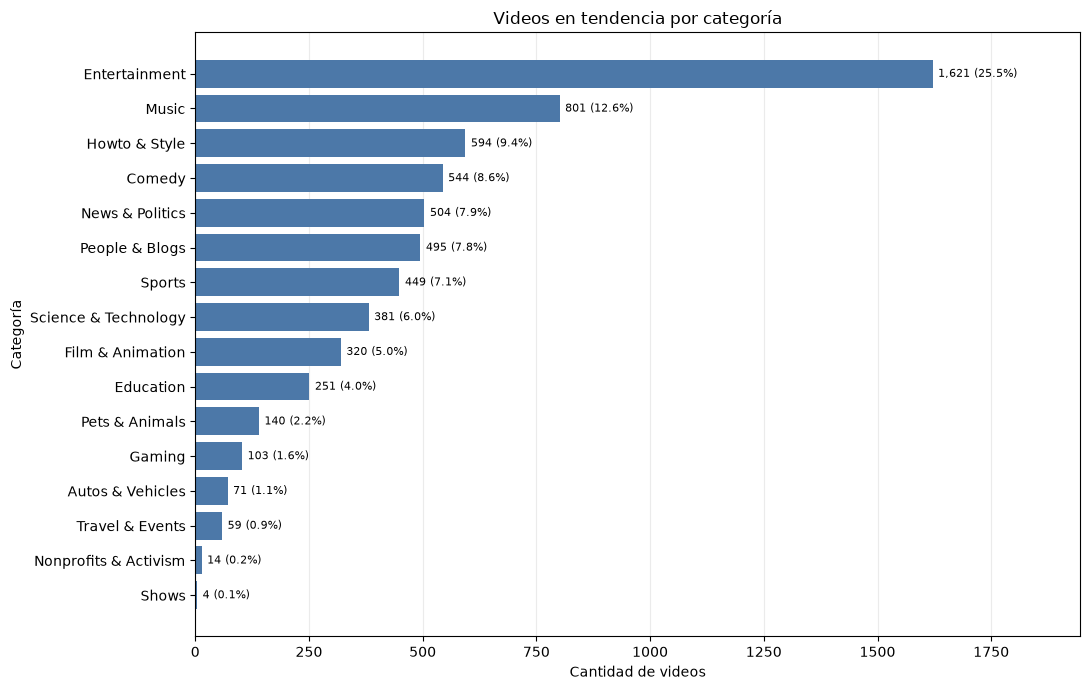

In [10]:
import matplotlib.pyplot as plt

query_dataset = 'select * from test.us_videos_daily;'
query_category = 'select * from test.us_category_id;'
dataset = read_from_postgres(query_dataset)
category = read_from_postgres(query_category)
last_data = (dataset.sort_values("trending_date").drop_duplicates(subset="video_id", keep="last"))
video_distribution_dataset = last_data.groupby("category_id")["video_id"].nunique().reset_index(name="total_videos")
video_distribution_dataset = video_distribution_dataset.merge(category, left_on="category_id", right_on="id", how="left")
video_distribution_dataset["percentage"] = (video_distribution_dataset["total_videos"] / video_distribution_dataset["total_videos"].sum()) * 100
video_distribution_dataset = video_distribution_dataset[["id", "title", "total_videos", "percentage"]]


plot_data = video_distribution_dataset.sort_values("total_videos", ascending=True)
fig, ax = plt.subplots(figsize=(11, 7))
bars = ax.barh(plot_data["title"], plot_data["total_videos"], color="#4C78A8")
labels = [
    f"{count:,} ({percentage:.1f}%)"
    for count, percentage in zip(
        plot_data["total_videos"], plot_data["percentage"]
    )
]
ax.bar_label(bars, labels=labels, padding=4, fontsize=8)
ax.set_title("Videos en tendencia por categoría")
ax.set_xlabel("Cantidad de videos")
ax.set_ylabel("Categoría")
ax.set_xlim(0, plot_data["total_videos"].max() * 1.2)
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

Se analizó la distribución de los 6.351 videos únicos entre las 16 categorías presentes en el dataset. Se encontró que **Entertainment** concentra la mayor cantidad de videos, con 1.621 registros (25,5 %), seguida de **Music**, con 801 (12,6 %). Estas dos categorías representan aproximadamente el 38,1 % del total. También se observa que la distribución disminuye considerablemente en las categorías con menor representación. Por ejemplo, **Nonprofits & Activism** cuenta con 14 videos y **Shows** con tan solo 4.

Esto evidencia que existe una concentración de videos en determinadas categorías y una representación mucho menor en otras. Esta diferencia deberá tenerse en cuenta al realizar comparaciones y análisis posteriores, especialmente en aquellas categorías con pocos registros.

### 5.2 Distribución de visualizaciones por video

,video_id,total_views
0,-0CMnp02rNY,800359
1,-0NYY8cqdiQ,563746
2,-1Hm41N0dUs,2058516
3,-1yT-K3c6YI,231341
4,-2RVw2_QyxQ,71089
...,...,...
6346,zwEn-ambXLw,241668
6347,zxUwbflE1SY,225280
6348,zxwfDlhJIpw,8442986
6349,zy0b9e40tK8,378750


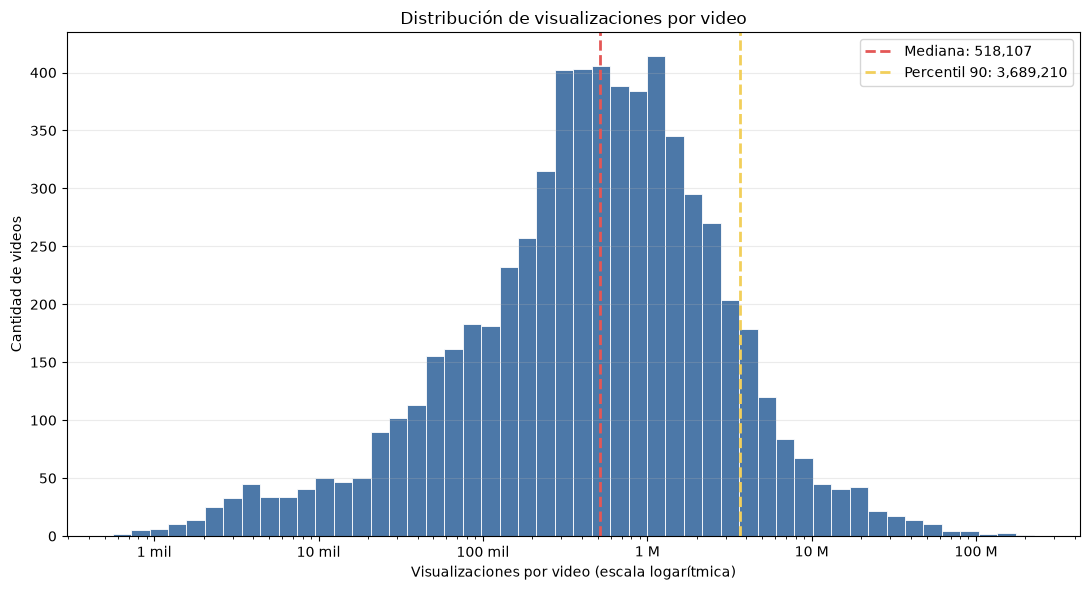

In [11]:
views_distribution_dataset = last_data.groupby("video_id")["views"].sum().reset_index(name="total_views")
display(views_distribution_dataset)
import numpy as np
from matplotlib.ticker import FuncFormatter

views = views_distribution_dataset["total_views"].dropna()
positive_views = views[views > 0]
zero_views = (views == 0).sum()
if positive_views.empty:
    raise ValueError("No hay visualizaciones positivas para mostrar en escala logarítmica.")

if positive_views.min() == positive_views.max():
    bins = 1
else:
    bins = np.geomspace(positive_views.min(), positive_views.max(), 51)

fig, ax = plt.subplots(figsize=(11, 6))
ax.hist(positive_views, bins=bins, color="#4C78A8", edgecolor="white", linewidth=0.6)
median_views = positive_views.median()
p90_views = positive_views.quantile(0.9)
ax.axvline(median_views, color="#E45756", linestyle="--", linewidth=2,
           label=f"Mediana: {median_views:,.0f}")
ax.axvline(p90_views, color="#F2CF5B", linestyle="--", linewidth=2,
           label=f"Percentil 90: {p90_views:,.0f}")
ax.set_xscale("log")

def format_views(value, _):
    if value >= 1_000_000:
        return f"{value / 1_000_000:g} M"
    if value >= 1_000:
        return f"{value / 1_000:g} mil"
    return f"{value:g}"

ax.xaxis.set_major_formatter(FuncFormatter(format_views))
ax.set_title("Distribución de visualizaciones por video")
ax.set_xlabel("Visualizaciones por video (escala logarítmica)")
ax.set_ylabel("Cantidad de videos")
ax.grid(axis="y", alpha=0.25)
ax.legend()
if zero_views:
    ax.text(0.99, 0.98, f"Videos con 0 visualizaciones: {zero_views}",
            transform=ax.transAxes, ha="right", va="top")
fig.tight_layout()
plt.show()

In [13]:
views_distribution_dataset["total_views"].describe(
    percentiles=[.25, .50, .75, .90, .95, .99]
)

count    6.351000e+03
mean     1.962117e+06
std      7.060057e+06
min      5.590000e+02
25%      1.591565e+05
50%      5.181070e+05
75%      1.473582e+06
90%      3.689210e+06
95%      6.718626e+06
99%      2.518920e+07
max      2.252119e+08
Name: total_views, dtype: float64

En la distribución de visualizaciones del último corte registrado por video (`last_data`) se observa una fuerte asimetría positiva (cola derecha larga): la mediana se ubica en **518.107 visualizaciones**, mientras que el percentil 90 alcanza **3,69 millones** y el percentil 99 supera los **25,18 millones**.

> **Nota metodológica:** Dado que `last_data` conserva únicamente la última observación disponible por `video_id`, las métricas reflejan el acumulado más reciente dentro de Trending (no la suma de días repetidos). Por esta razón, en el modelado posterior se aplicará transformación logarítmica (`log1p`) para estabilizar la varianza.

### 5.3 Rendimiento e interacción por categoría

,title_category,videos,median_views,median_likes,median_engagement_pct,median_like_ratio_pct,avg_days_trending
5,Gaming,103,1316002.0,36922.0,3.54,96.35,7.92
7,Music,801,1096158.0,39940.0,3.81,97.74,8.08
4,Film & Animation,320,910969.5,11905.0,2.25,95.77,7.33
1,Comedy,544,790545.5,22900.5,3.40,96.81,6.34
3,Entertainment,1621,606048.0,11733.0,2.25,96.00,6.14
11,Pets & Animals,140,434946.0,11601.0,3.34,98.20,6.64
12,Science & Technology,381,429830.0,11229.0,2.89,96.49,6.30
6,Howto & Style,594,426985.0,15910.0,4.32,97.61,6.97
14,Sports,449,405781.0,4293.0,1.29,94.66,4.82
10,People & Blogs,495,403844.0,13166.0,3.40,97.47,6.47


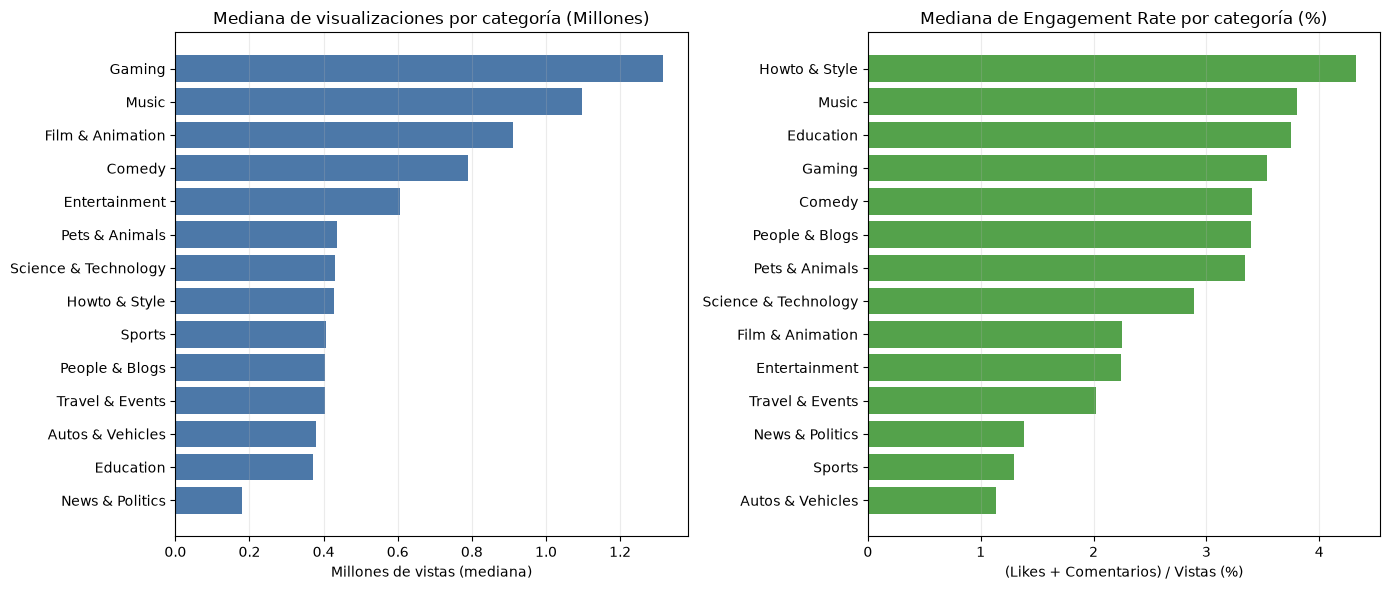

In [ ]:
import seaborn as sns

video_df = last_data.merge(
    category[["id", "title", "assignable"]],
    left_on="category_id",
    right_on="id",
    how="left",
    suffixes=("", "_category")
)

trending_stats = dataset.groupby("video_id").agg(
    days_in_trending=("trending_date", "nunique"),
    first_trending_date=("trending_date", "min"),
    initial_views=("views", "min")
).reset_index()

video_df = video_df.merge(trending_stats, on="video_id", how="left")

video_df["engagement_rate"] = (
    (video_df["likes"] + video_df["comment_count"]) / video_df["views"].replace(0, np.nan)
) * 100
video_df["like_ratio"] = (
    video_df["likes"] / (video_df["likes"] + video_df["dislikes"]).replace(0, np.nan)
) * 100

# Resumen por categoría (filtrando categorías con al menos 20 videos para estabilidad estadística)
cat_summary = video_df.groupby("title_category").agg(
    videos=("video_id", "count"),
    median_views=("views", "median"),
    median_likes=("likes", "median"),
    median_engagement_pct=("engagement_rate", "median"),
    median_like_ratio_pct=("like_ratio", "median"),
    avg_days_trending=("days_in_trending", "mean")
).reset_index()

cat_summary_filtered = cat_summary[cat_summary["videos"] >= 20].sort_values(
    "median_views", ascending=False
)
display(cat_summary_filtered.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

plot_views = cat_summary_filtered.sort_values("median_views", ascending=True)
axes[0].barh(plot_views["title_category"], plot_views["median_views"] / 1e6, color="#4C78A8")
axes[0].set_title("Mediana de visualizaciones por categoría (Millones)")
axes[0].set_xlabel("Millones de vistas (mediana)")
axes[0].grid(axis="x", alpha=0.25)

plot_eng = cat_summary_filtered.sort_values("median_engagement_pct", ascending=True)
axes[1].barh(plot_eng["title_category"], plot_eng["median_engagement_pct"], color="#54A24B")
axes[1].set_title("Mediana de Engagement Rate por categoría (%)")
axes[1].set_xlabel("(Likes + Comentarios) / Vistas (%)")
axes[1].grid(axis="x", alpha=0.25)

fig.tight_layout()
plt.show()

### 5.4 Tiempo hasta Trending y estacionalidad


Distribución de días hasta llegar a Trending (percentiles):


count    6351.000000
mean       22.524957
std       209.963512
min         0.000000
25%         1.000000
50%         2.000000
75%         3.000000
90%         4.000000
95%         6.000000
max      4215.000000
Name: days_to_trending, dtype: float64

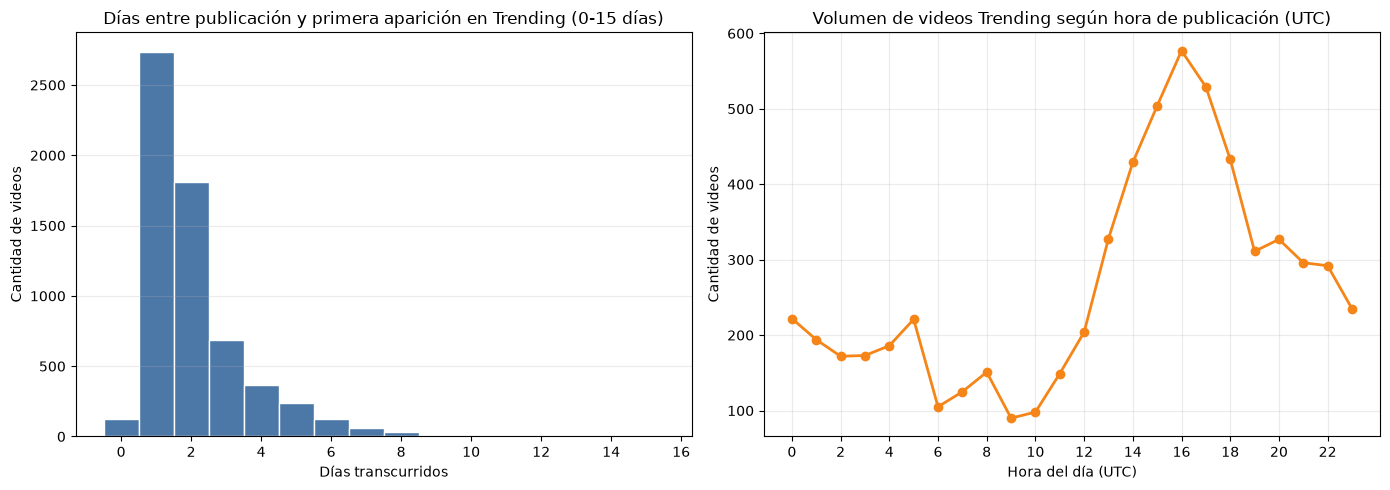

In [ ]:
video_df["publish_time_dt"] = pd.to_datetime(video_df["publish_time"])
video_df["first_trending_dt"] = pd.to_datetime(video_df["first_trending_date"])

video_df["days_to_trending"] = (
    video_df["first_trending_dt"].dt.normalize() - video_df["publish_time_dt"].dt.normalize()
).dt.days.clip(lower=0)

video_df["publish_hour"] = video_df["publish_time_dt"].dt.hour
video_df["publish_dow"] = video_df["publish_time_dt"].dt.day_name()

print("Distribución de días hasta llegar a Trending (percentiles):")
display(video_df["days_to_trending"].describe(percentiles=[.25, .50, .75, .90, .95]))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

fast_trending = video_df[video_df["days_to_trending"] <= 15]["days_to_trending"]
axes[0].hist(fast_trending, bins=range(0, 17), align="left", color="#4C78A8", edgecolor="white")
axes[0].set_title("Días entre publicación y primera aparición en Trending (0-15 días)")
axes[0].set_xlabel("Días transcurridos")
axes[0].set_ylabel("Cantidad de videos")
axes[0].grid(axis="y", alpha=0.25)

hourly_counts = video_df.groupby("publish_hour")["video_id"].count()
axes[1].plot(hourly_counts.index, hourly_counts.values, marker="o", color="#F58518", linewidth=2)
axes[1].set_title("Volumen de videos Trending según hora de publicación (UTC)")
axes[1].set_xlabel("Hora del día (UTC)")
axes[1].set_ylabel("Cantidad de videos")
axes[1].set_xticks(range(0, 24, 2))
axes[1].grid(True, alpha=0.25)

fig.tight_layout()
plt.show()

## 7. Clustering

Para responder si existen agrupaciones naturales de videos más allá de las categorías tradicionales de YouTube, se aplica **K-Means** sobre métricas estandarizadas de escala e interacción (`log1p(views)`, `engagement_rate`, `like_ratio`, `days_in_trending`).

Esta segmentación permite distinguir entre:
1. **Contenido viral masivo** (alto alcance, interacción moderada).
2. **Contenido de nicho altamente comprometido** (alcance medio, altísima tasa de likes y comentarios: ideal para *sponsors* de conversión).
3. **Contenido polémico o de baja resonancia** (menor aprobación o permanencia breve en tendencia).

Silhouette Score por número de clusters: {3: 0.2594, 4: 0.2865, 5: 0.2817}


,videos,median_views,median_likes,median_engagement_pct,median_like_ratio_pct,avg_days_trending
cluster,,,,,,
0,3109,296315.0,5224.0,2.10,95.80,3.99
1,1655,1987241.0,43626.0,2.77,96.40,11.91
2,392,156059.5,824.5,1.11,60.02,4.92
3,1164,437878.5,28061.0,6.90,98.61,5.73


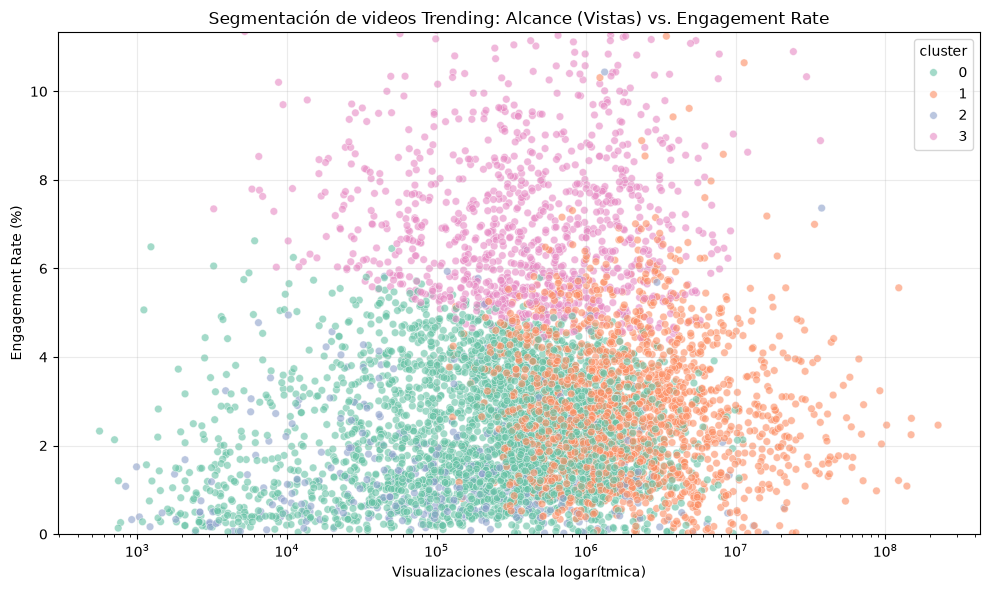

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

cluster_features = ["views", "engagement_rate", "like_ratio", "days_in_trending"]
cluster_data = video_df.dropna(subset=cluster_features).copy()
cluster_data["log_views"] = np.log1p(cluster_data["views"])

X_cluster = cluster_data[["log_views", "engagement_rate", "like_ratio", "days_in_trending"]]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

sil_scores = {}
for k in range(3, 6):
    km_tmp = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_tmp = km_tmp.fit_predict(X_scaled)
    sil_scores[k] = round(silhouette_score(X_scaled, labels_tmp), 4)

print("Silhouette Score por número de clusters:", sil_scores)

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
cluster_data["cluster"] = kmeans.fit_predict(X_scaled)

cluster_profile = cluster_data.groupby("cluster").agg(
    videos=("video_id", "count"),
    median_views=("views", "median"),
    median_likes=("likes", "median"),
    median_engagement_pct=("engagement_rate", "median"),
    median_like_ratio_pct=("like_ratio", "median"),
    avg_days_trending=("days_in_trending", "mean")
).round(2)

display(cluster_profile)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=cluster_data,
    x="views",
    y="engagement_rate",
    hue="cluster",
    palette="Set2",
    alpha=0.6,
    s=30
)
plt.xscale("log")
plt.ylim(0, cluster_data["engagement_rate"].quantile(0.98))
plt.title("Segmentación de videos Trending: Alcance (Vistas) vs. Engagement Rate")
plt.xlabel("Visualizaciones (escala logarítmica)")
plt.ylabel("Engagement Rate (%)")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

## 8. Modelado Predictivo: Estimación de Alcance y Likes


In [27]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

model_df = video_df[video_df["ratings_disabled"] == 'f'].copy()

num_features = [
    "tag_count", "title_len", "title_word_count", "title_has_punct",
    "title_upper_ratio", "desc_len", "has_url", "url_count",
    "publish_hour", "channel_video_count"
]
cat_features = ["title_category", "publish_dow"]

X = model_df[num_features + cat_features]
y_likes = np.log1p(model_df["likes"])
y_views = np.log1p(model_df["views"])

X_train, X_test, y_train_l, y_test_l, y_train_v, y_test_v = train_test_split(
    X, y_likes, y_views, test_size=0.2, random_state=42
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features)
    ]
)

models = {
    "Random Forest": RandomForestRegressor(n_estimators=200, max_depth=12, random_state=42, n_jobs=-1)
}

results = []
for target_name, y_tr, y_te in [
    ("log1p(likes)", y_train_l, y_test_l),
    ("log1p(views)", y_train_v, y_test_v)
]:
    for model_name, reg in models.items():
        pipe = Pipeline([("prep", preprocessor), ("model", reg)])
        pipe.fit(X_train, y_tr)
        preds = pipe.predict(X_test)
        results.append({
            "Variable Objetivo": target_name,
            "Modelo": model_name,
            "MAE (log)": round(mean_absolute_error(y_te, preds), 4),
            "RMSE (log)": round(root_mean_squared_error(y_te, preds), 4),
            "R2": round(r2_score(y_te, preds), 4)
        })

display(pd.DataFrame(results))


,Variable Objetivo,Modelo,MAE (log),RMSE (log),R2
0,log1p(likes),Random Forest,1.2961,1.7492,0.4066
1,log1p(views),Random Forest,1.2409,1.6486,0.2558
